# More efficient plants, less electricity?

Economic Analysis for Data Scientists, Assignment 2

**Author:** José Luis Fernández Huaita, Francesca Alexandra Panga, Xave Markey

## Setup

In [62]:
# 0.1 Packages and data
# Installs any missing package into the kernel you selected (only the first time).
import importlib.util, subprocess, sys
for package in ["numpy", "pandas", "matplotlib", "scipy"]:
    if importlib.util.find_spec(package) is None:
        print(f"Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Finds energy_firms.csv next to the notebook (in data/ or directly), or in a nearby folder
from pathlib import Path

def find_data(name="energy_firms.csv"):
    here = Path.cwd()
    candidates = [here / "data" / name, here / name]
    for folder in list(here.parents)[:2]:
        candidates += [folder / "data" / name, folder / name]
    for path in candidates:
        if path.exists():
            return path
    for path in here.rglob(name):          # search sub-folders of the notebook's folder
        return path
    raise FileNotFoundError(
        f"Could not find {name}. Put it in a folder called 'data' next to this notebook "
        f"(the notebook is running in: {here})."
    )

DATA_PATH = find_data()
print("Data file:", DATA_PATH)
energy = pd.read_csv(DATA_PATH)

group_colours = {"Control": "#52514e", "Treated": "#2a78d6"}
sector_colours = {"Chemicals": "#eb6834", "Textiles": "#1baf7a"}
groups = ["Control", "Treated"]
sectors = ["Chemicals", "Textiles"]

Data file: /Users/xave/Desktop/econ/hw2_insurance_econ/data/energy_firms.csv


In [63]:
# 0.2 Variables we construct
# - group: readable treatment label
# - window: the four periods we compare (pre-programme and three post windows)
# - *_base: each plant's average over the four pre-programme months (-3 to 0)
# - dlog_*: log change relative to the plant's own baseline (0.10 is roughly +10%)
# The data are re-read here so that this cell can be run more than once.

energy = pd.read_csv(DATA_PATH)
energy["group"] = np.where(energy["treated"] == 1, "Treated", "Control")

window_labels = ["Pre (-3 to 0)", "Months 1-3", "Months 4-7", "Months 8-12"]
energy["window"] = pd.cut(energy["month"], bins=[-np.inf, 0, 3, 7, np.inf], labels=window_labels)

baseline = (energy[energy["month"] <= 0]
            .groupby("firm_id")[["output", "labor", "electricity"]]
            .mean()
            .add_suffix("_base"))
energy = energy.join(baseline, on="firm_id")

energy["dlog_E"] = np.log(energy["electricity"] / energy["electricity_base"])
energy["dlog_L"] = np.log(energy["labor"] / energy["labor_base"])
energy["dlog_Q"] = np.log(energy["output"] / energy["output_base"])

# One row per plant: fixed characteristics and baseline (pre-programme) means
plants = (energy[energy["month"] <= 0]
          .groupby(["firm_id", "sector", "treated", "group", "adjust_month"])
          [["output", "labor", "electricity", "output_price", "wage", "energy_price"]]
          .mean()
          .reset_index())
plants["energy_cost_share"] = (plants["energy_price"] * plants["electricity"] /
                               (plants["wage"] * plants["labor"] + plants["energy_price"] * plants["electricity"]))

energy.info()

<class 'pandas.DataFrame'>
RangeIndex: 7680 entries, 0 to 7679
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   firm_id           7680 non-null   str     
 1   sector            7680 non-null   str     
 2   treated           7680 non-null   int64   
 3   month             7680 non-null   int64   
 4   adjust_month      7680 non-null   int64   
 5   labor_adjustable  7680 non-null   int64   
 6   output            7680 non-null   float64 
 7   labor             7680 non-null   float64 
 8   electricity       7680 non-null   float64 
 9   output_price      7680 non-null   float64 
 10  wage              7680 non-null   float64 
 11  energy_price      7680 non-null   float64 
 12  group             7680 non-null   str     
 13  window            7680 non-null   category
 14  output_base       7680 non-null   float64 
 15  labor_base        7680 non-null   float64 
 16  electricity_base  7680 non-null   f

In [64]:
# 0.3 Helper functions
# balance_table: compares treated and control plants variable by variable, in levels and in logs
# (the variables are very skewed, so the log comparison is more informative).
# p-values come from Welch t-tests with one observation per plant.

def balance_table(data, variables):
    rows = []
    for v in variables:
        control = data.loc[data["treated"] == 0, v]
        treated = data.loc[data["treated"] == 1, v]
        rows.append({
            "variable": v,
            "n_control": len(control),
            "mean_control": control.mean(),
            "n_treated": len(treated),
            "mean_treated": treated.mean(),
            "difference": treated.mean() - control.mean(),
            "p_value": stats.ttest_ind(treated, control, equal_var=False).pvalue,
            "diff_logs": np.log(treated).mean() - np.log(control).mean(),
            "p_value_logs": stats.ttest_ind(np.log(treated), np.log(control), equal_var=False).pvalue,
        })
    return pd.DataFrame(rows).round(3)


# pct: turns a mean log change into a percentage change, 100 * (exp(x) - 1)
def pct(x):
    return 100 * (np.exp(x) - 1)


# mean_and_ci_by: mean of a column by group, with a 95% interval across observations
def mean_and_ci_by(data, by, column):
    out = data.groupby(by)[column].agg(["mean", "std", "size"]).reset_index()
    out["se"] = out["std"] / np.sqrt(out["size"])
    out["low"] = out["mean"] - 1.96 * out["se"]
    out["high"] = out["mean"] + 1.96 * out["se"]
    return out

In [78]:
# Codebook: what each variable is and how it behaves in the data
pd.set_option("display.max_colwidth", None)
raw = pd.read_csv(DATA_PATH)

codebook = pd.DataFrame([
    ("firm_id",          "Plant identifier",                                    "—"),
    ("sector",           "Textiles or Chemicals",                               "—"),
    ("treated",          "Consulting assignment (1 = consulting, 0 = control)", "—"),
    ("month",            "Month relative to programme start (-3 to 12)",       "month"),
    ("adjust_month",     "Staffing-review month: labour can adjust from here",   "month"),
    ("labor_adjustable", "1 if labour can be adjusted that month, 0 if fixed",   "—"),
    ("output",           "Output q",                                            "batches / month"),
    ("labor",            "Labour L",                                            "blocks of 100 worker-hours / month"),
    ("electricity",      "Electricity E",                                       "MWh / month"),
    ("output_price",     "Output price p",                                      "CU per batch"),
    ("wage",             "Wage w",                                              "CU per labour block"),
    ("energy_price",     "Electricity price c",                                 "CU per MWh"),
], columns=["variable", "meaning", "unit"])

def describe(v):
    x = raw[v]
    changes_within_plant = (raw.groupby("firm_id")[v].nunique() > 1).any()
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > 16:
        values = f"{x.min():,.1f} to {x.max():,.1f}"
    elif pd.api.types.is_numeric_dtype(x) and x.nunique() > 5:
        values = f"{x.min()} to {x.max()}"
    else:
        values = ", ".join(map(str, sorted(x.unique())[:4])) + (" ..." if x.nunique() > 4 else "")
    return pd.Series({"values": values,
                      "changes over time within a plant": "yes" if changes_within_plant else "no"})

codebook = codebook.join(codebook["variable"].apply(describe))
display(codebook)

,variable,meaning,unit,values,changes over time within a plant
0,firm_id,Plant identifier,—,"F001, F002, F003, F004 ...",no
1,sector,Textiles or Chemicals,—,"Chemicals, Textiles",no
2,treated,"Consulting assignment (1 = consulting, 0 = control)",—,"0, 1",no
3,month,Month relative to programme start (-3 to 12),month,-3 to 12,yes
4,adjust_month,Staffing-review month: labour can adjust from here,month,"4, 6, 8",no
5,labor_adjustable,"1 if labour can be adjusted that month, 0 if fixed",—,"0, 1",yes
6,output,Output q,batches / month,29.0 to 254.9,yes
7,labor,Labour L,blocks of 100 worker-hours / month,57.1 to 702.4,yes
8,electricity,Electricity E,MWh / month,"923.4 to 18,213.8",yes
9,output_price,Output price p,CU per batch,"5,304.6 to 83,851.9",no


# Part 1: Explore electricity use before and after consulting

## 1. Explore and check the data.

Present evidence about these plants’ electricity consumption before and after the programme begins. You might examine averages, distributions, individual trajectories or changes relative to each plant’s baseline. There is no single correct presentation: choose the comparisons and visualisations you find informative, and explain what they reveal.

As part of your exploration, check the sample, panel structure, units and treatment assignment. Note any data issues or important differences across plants. You do not need to propose an economic explanation yet.

**Overview of Section 1**

* **1.1 The data is clean and the design is as described.** 480 plants × 16 months, no missing values or duplicates, 40 treated and 40 control plants in every sector per staffing-review cohort. Prices are constant within each plant, and units of labour is fixed except for their assigned adjustment month (4, 6, or 8).
* **1.2 Treated plants are slightly larger at baseline, by chance.** Labour and output are 6–8% higher (p < 0.05 in logs), although the groups are jointly balanced. Every outcome will be measured relative to each plant's own baseline.
* **1.3 Plants electricity levels vary between plants and over time.** Between plants baseline electricity ranges from about 1,300 to 17,500 MWh a month and electricity prices vary 40 times that, so analysis will consider proportional changes and report totals separately. Baseline electricity levels are similar between the control and treatment group prior to the consulting period. The control group's electricity level remains the same throughout the 16 months. However the treatment group's electricty levels start to decrease when the consulting period starts until month three. Then the electricty level starts to increase from month three to seven until it is almost back to the starting level of electricty usage. From month eight to month twelve, the electricty level surpasses the baseline electricty level.

### 1.1 Data Overview

As in any randomised evaluation, we first check that the data support the comparison we want to make:
* Equal number of plants per treatment group per industry and clean data
* Each firm has 16 observations, one for each month of the study
* The groups assigned to the treatment and control were comparable at baseline. 
* Programme rules implemented as described (constant prices, labour fixed until the review month)
* No common shocks affecting all plants


##### 1.1.1 Balanced panel and clean data
Every plant is observed in all 16 months (−3 to 12): 4 months before the programme and 12 after. There are no missing values or duplicated plant-months.

In [65]:
display(pd.DataFrame({
    "rows": [len(energy)],
    "plants": [energy["firm_id"].nunique()],
    "months": [energy["month"].nunique()],
    "missing_values": [energy.isna().sum().sum()],
    "duplicated_plant_months": [energy.duplicated(["firm_id", "month"]).sum()],
}))

# Number of months observed per plant
display(energy.groupby("firm_id").size().value_counts()
        .rename_axis("months_observed").reset_index(name="plants"))

,rows,plants,months,missing_values,duplicated_plant_months
0,7680,480,16,0,0


,months_observed,plants
0,16,480


##### 1.1.2 Treatment assignment and baseline balance
Assignment was randomised within each sector and staffing-review cohort. Each of the six cells has exactly 40 treated and 40 control plants.

Before treatment was implemented there was a significant difference between the amount of labor in the control and treatment groups (with the treatment group having about 8% more). Before treatment was implemented there was a significant difference between the amount of output in the control and treatment groups (with the treatment group having about 6% more).  A joint test does not reject balance (p ≈ 0.28), so this looks like chance imbalance rather than a problem with the randomisation. It still matters for how to measure effects: comparing post-programme **levels** would mix the programme with these baseline differences. Each plant will be compared with its own baseline (and, in Question 3, treated with control changes). 
* For significance levels, p-value log was employed due to a focus on comparable differences between groups, not on absolutes.

In [66]:
# Plants per sector, staffing-review cohort and group
display(pd.crosstab([plants["sector"], plants["adjust_month"]], plants["group"]))

# Baseline balance, one observation per plant (average of months -3 to 0)
display(balance_table(plants, ["electricity", "labor", "output", "output_price", "wage", "energy_price"]))

# Joint test: do baseline characteristics predict treatment? (F-test from an OLS regression)
log_vars = ["electricity", "labor", "output", "output_price", "wage", "energy_price"]
X = np.column_stack([np.ones(len(plants))] + [np.log(plants[v]) for v in log_vars])
y = plants["treated"].to_numpy()
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
rss = ((y - X @ beta) ** 2).sum()
tss = ((y - y.mean()) ** 2).sum()
k, n = len(log_vars), len(y)
F = ((tss - rss) / k) / (rss / (n - k - 1))
display(pd.DataFrame({"F_statistic": [round(F, 2)], "p_value": [round(stats.f.sf(F, k, n - k - 1), 3)]}))

group                   Control  Treated
sector    adjust_month                  
Chemicals 4                  40       40
          6                  40       40
          8                  40       40
Textiles  4                  40       40
          6                  40       40
          8                  40       40

,variable,n_control,mean_control,n_treated,mean_treated,difference,p_value,diff_logs,p_value_logs
0,electricity,240,4108.708,240,4413.708,305.000,0.103,0.076,0.059
1,labor,240,161.888,240,174.581,12.693,0.042,0.087,0.013
2,output,240,76.595,240,80.871,4.276,0.053,0.060,0.032
3,output_price,240,22714.275,240,23341.821,627.545,0.594,0.013,0.785
4,wage,240,1415.703,240,1404.892,-10.811,0.498,-0.007,0.527
5,energy_price,240,163.687,240,162.973,-0.714,0.945,-0.013,0.840


,F_statistic,p_value
0,1.25,0.278


##### 1.1.3 Programme rules implemented as described
* Sector, treatment, review month and all three prices are constant within every plant.
* `labor_adjustable` follows the institutional rule exactly: labour is adjustable before month 1 and from the review month onwards.
* While labour is fixed, it stays at its baseline level in both groups. The month-to-month variation (about 1.6%). Because this number is so small, labour will be assumed to fixed as described in the programme.

In [67]:
# Plants in which each characteristic takes more than one value (should be 0)
n_values = energy.groupby("firm_id")[["sector", "treated", "adjust_month",
                                      "output_price", "wage", "energy_price"]].nunique()
display((n_values > 1).sum().to_frame("plants_with_more_than_one_value"))

# labor_adjustable should equal 1 before month 1 and from the review month on
rule = ((energy["month"] <= 0) | (energy["month"] >= energy["adjust_month"])).astype(int)
display(pd.DataFrame({"rows": [len(energy)],
                      "rows_matching_rule": [(rule == energy["labor_adjustable"]).sum()]}))

# Labour relative to baseline while it is fixed
display(energy[energy["labor_adjustable"] == 0]
        .groupby("group")["dlog_L"]
        .agg(plant_months="size", mean_dlog_L="mean", sd_dlog_L="std")
        .round(4))

,plants_with_more_than_one_value
sector,0
treated,0
adjust_month,0
output_price,0
wage,0
energy_price,0


,rows,rows_matching_rule
0,7680,7680


,plant_months,mean_dlog_L,sd_dlog_L
group,,,
Control,1200,0.0003,0.0163
Treated,1200,0.0000,0.0159


##### 1.1.4 Size of the recording errors
Within each plant, quantities vary by only 1–2% across the four baseline months, when nothing should change. This is the recording noise mentioned in the brief. It is small relative to the changes studied, but it is a reason to average several months rather than rely on a single one.

In [68]:
# Mean within-plant coefficient of variation over months -3 to 0 (%)
pre = energy[energy["month"] <= 0].groupby("firm_id")[["output", "labor", "electricity"]]
display((100 * (pre.std() / pre.mean()).mean()).round(2).to_frame("mean_cv_pct"))

,mean_cv_pct
output,1.65
labor,1.27
electricity,1.84


### 1.2 Differences across plants

**Units.** Output is in standardised batches, labour in blocks of 100 paid worker-hours and electricity in MWh, all monthly totals; prices are in CU per batch, per labour block and per MWh.

Observations:
* **Size.** Baseline electricity ranges from about 1,300 to 17,500 MWh a month (median about 3,800). The largest 10% of plants use about 21% of all electricity, so totals are weighted towards large plants (right skewed).
* **Prices.** Wages are similar across sectors (about 1,400 CU per block). Electricity is more expensive and more dispersed in Chemicals than Textiles (mean 186 vs 140 CU/MWh), with a range of roughly 20 to 835 CU/MWh.
* **Output and electricity prices move together.** Across plants, output and electricity prices are correlated (r = 0.77 in logs). Output price and electricity less correlated (r = 0.29), due to the difference in productivity and size; this is a cross-plant correlation, not a causal relationship.
* **Electricity is the main variable cost.** Electricity makes up more than half of variable costs at most plants, with Chemicals concentrated at high shares and Textiles more dispersed, including a tail of labour-intensive plants. The programme may affect plants differently depending on their electricity intensity.

In [69]:
# Summary by sector, one observation per plant
summary_vars = ["electricity", "labor", "output", "output_price", "wage", "energy_price", "energy_cost_share"]
display(plants.melt(id_vars="sector", value_vars=summary_vars)
        .groupby(["variable", "sector"])["value"]
        .agg(["mean", "median", "min", "max"])
        .map(lambda x: float(f"{x:.4g}")))

# Share of total baseline electricity used by the largest 10% of plants
largest = plants["electricity"].sort_values(ascending=False)
top_n = round(0.1 * len(largest))
print("Share of electricity used by the largest 10% of plants:",
      round(largest.head(top_n).sum() / largest.sum(), 3))

mean      median        min         max
variable          sector                                                  
electricity       Chemicals   4196.0000   3756.0000  1258.0000  13190.0000
                  Textiles    4327.0000   3747.0000  1414.0000  17530.0000
energy_cost_share Chemicals      0.7156      0.7302     0.3988      0.8914
                  Textiles       0.6512      0.6702     0.3099      0.8890
energy_price      Chemicals    186.3000    152.7000    33.0000    834.9000
                  Textiles     140.3000    119.4000    20.9100    596.2000
labor             Chemicals    166.4000    152.5000    61.8900    374.8000
                  Textiles     170.0000    153.5000    58.4200    551.8000
output            Chemicals     78.9300     76.7700    33.5500    193.7000
                  Textiles      78.5300     73.1500    29.5300    183.2000
output_price      Chemicals  25150.0000  21340.0000  5695.0000  83850.0000
                  Textiles   20910.0000  18520.0000  5305.0000  66000.0000
wage              Chemicals   1398.0000   1394.0000  1064.0000   1926.0000
                  Textiles    1423.0000   1395.0000  1032.0000   2047.0000

Share of electricity used by the largest 10% of plants: 0.206


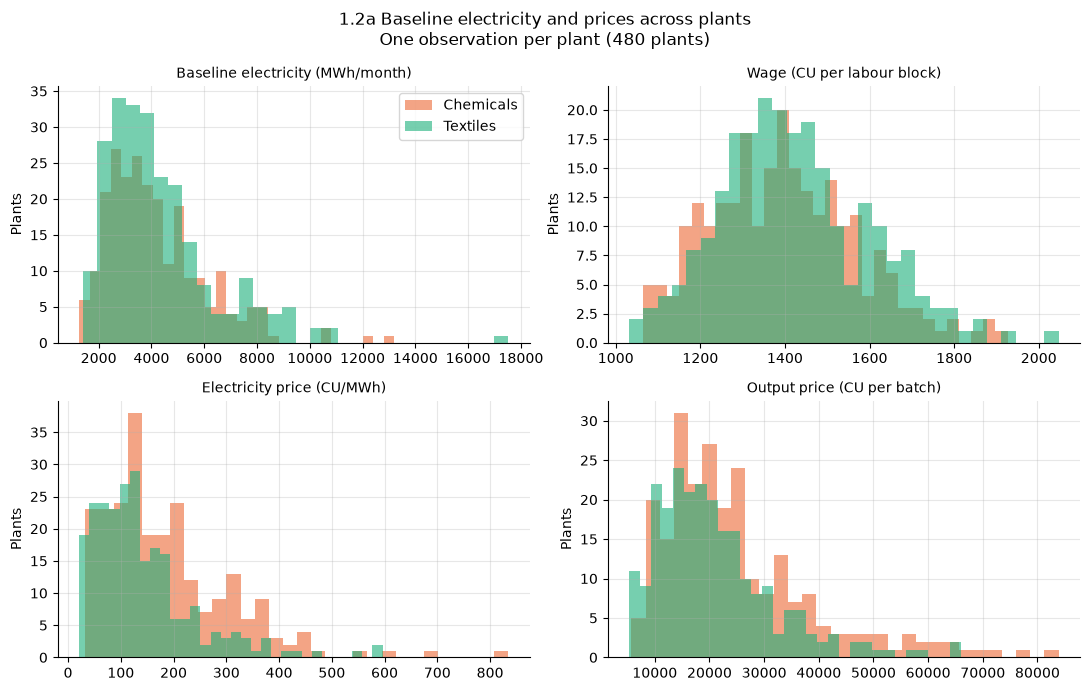

In [70]:
# Distribution of prices and baseline electricity, by sector
variables = {"electricity": "Baseline electricity (MWh/month)", "wage": "Wage (CU per labour block)",
             "energy_price": "Electricity price (CU/MWh)", "output_price": "Output price (CU per batch)"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (v, label) in zip(axes.flat, variables.items()):
    for s in sectors:
        ax.hist(plants.loc[plants["sector"] == s, v], bins=30, alpha=0.6, color=sector_colours[s], label=s)
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Plants")
axes[0, 0].legend()
fig.suptitle("1.2a Baseline electricity and prices across plants\n"
             "One observation per plant (480 plants)", fontsize=12)
fig.tight_layout()
plt.show()

,cor_logs_output_price_energy_price,cor_logs_output_price_electricity
0,0.77,0.29


,cor_logs_output_price_energy_price,cor_logs_output_price_electricity
0,0.77,0.29


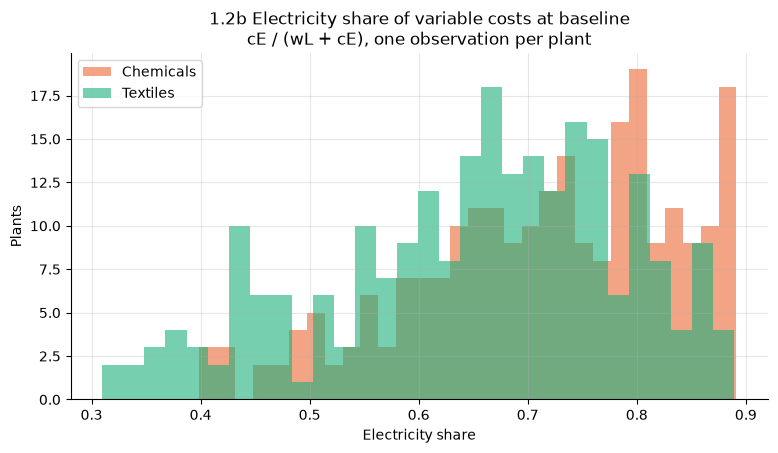

In [74]:
# Output price against electricity price and against baseline electricity (log scales)
display(pd.DataFrame({
    "cor_logs_output_price_energy_price": [round(np.corrcoef(np.log(plants["output_price"]), np.log(plants["energy_price"]))[0, 1], 2)],
    "cor_logs_output_price_electricity": [round(np.corrcoef(np.log(plants["output_price"]), np.log(plants["electricity"]))[0, 1], 2)],
}))
# Distribution of prices and baseline electricity, by sector
variables = {"electricity": "Baseline electricity (MWh/month)", "wage": "Wage (CU per labour block)",
             "energy_price": "Electricity price (CU/MWh)", "output_price": "Output price (CU per batch)"}

# Correlations across plants between output price, electricity price and electricity use (in logs)
display(pd.DataFrame({
    "cor_logs_output_price_energy_price": [round(np.corrcoef(np.log(plants["output_price"]), np.log(plants["energy_price"]))[0, 1], 2)],
    "cor_logs_output_price_electricity": [round(np.corrcoef(np.log(plants["output_price"]), np.log(plants["electricity"]))[0, 1], 2)],
}))

# Share of electricity in the cost of labour plus electricity
fig, ax = plt.subplots(figsize=(9, 4.5))
for s in sectors:
    ax.hist(plants.loc[plants["sector"] == s, "energy_cost_share"], bins=30, alpha=0.6,
            color=sector_colours[s], label=s)
ax.set_title("1.2b Electricity share of variable costs at baseline\ncE / (wL + cE), one observation per plant")
ax.set_xlabel("Electricity share")
ax.set_ylabel("Plants")
ax.legend()
plt.show()

### 1.3 Electricity before and after the programme starts

Because plants differ so much in size, each plant's electricity is measured relative to its own baseline in MWh, which is what matters for aggregate consumption.

Observations:
* **Control plants are flat** throughout the 16 months, so there is no common shock affecting all plants.
* **Treated plants fall immediately when the consulting period begins.** In months 1–3, electricity is about 26% below baseline.
* **Electricty level among treated plants begins to rise** In months 4–7 the firms begin to increase electricity levels, until they are almost to the baseline prior to treastment. By months 8–12, treated plants use about 9% *more* electricity than at baseline.
* **Totals tell the same story.** Total electricity of treated plants is 26% lower in months 1–3, 7% lower in months 4–7 and 10% higher in months 8–12. The total changes differ slightly from the average plant's change because larger plants weigh more in the total.
* **Plants differ in how far they rebound.** By months 8–12, about one in six treated plants is still below baseline.
* **Similar Behavior in Chemical and Textile Plants** Electricity usage by month was compared between chemical and textile plants and the same pattern of a decrease in electricty usage followed by a rise was found. 


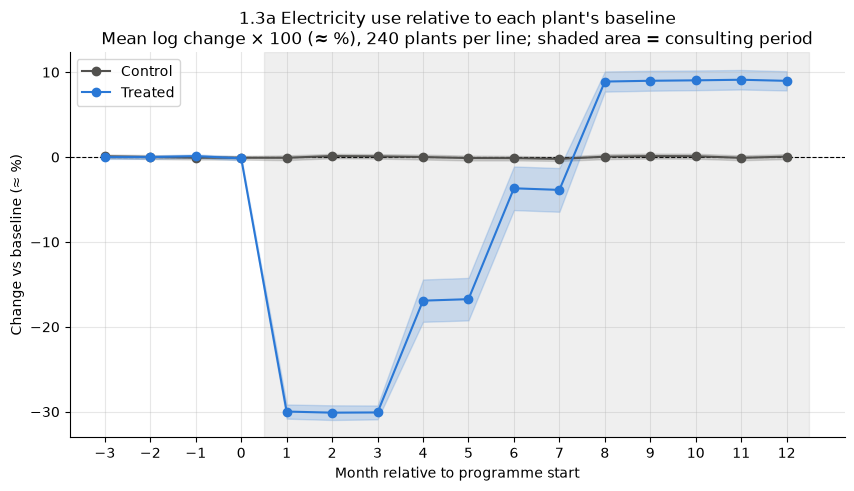

In [42]:
# Mean change relative to own baseline, by month and group, with 95% intervals across plants
by_month = mean_and_ci_by(energy, ["month", "group"], "dlog_E")

fig, ax = plt.subplots()
ax.axvspan(0.5, 12.5, color="grey", alpha=0.12)
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
for g in groups:
    d = by_month[by_month["group"] == g]
    ax.fill_between(d["month"], 100 * d["low"], 100 * d["high"], color=group_colours[g], alpha=0.2)
    ax.plot(d["month"], 100 * d["mean"], marker="o", color=group_colours[g], label=g)
ax.set_xticks(range(-3, 13))
ax.set_xlabel("Month relative to programme start")
ax.set_ylabel("Change vs baseline (≈ %)")
ax.set_title("1.3a Electricity use relative to each plant's baseline\n"
             "Mean log change × 100 (≈ %), 240 plants per line; shaded area = consulting period")
ax.legend()
plt.show()

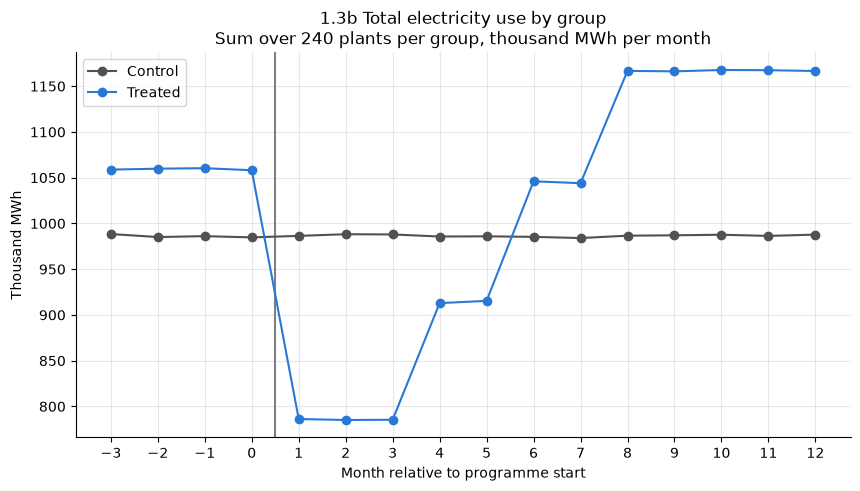

In [43]:
# Total electricity by month and group (thousand MWh)
totals = energy.groupby(["month", "group"])["electricity"].sum().div(1000).reset_index()

fig, ax = plt.subplots()
ax.axvline(0.5, color="grey")
for g in groups:
    d = totals[totals["group"] == g]
    ax.plot(d["month"], d["electricity"], marker="o", color=group_colours[g], label=g)
ax.set_xticks(range(-3, 13))
ax.set_xlabel("Month relative to programme start")
ax.set_ylabel("Thousand MWh")
ax.set_title("1.3b Total electricity use by group\nSum over 240 plants per group, thousand MWh per month")
ax.legend()
plt.show()

In [44]:
# Summary by window: average plant's change and change in total electricity
plant_windows = (energy.groupby(["firm_id", "group", "window"], observed=True)
                 .agg(electricity=("electricity", "mean"), dlog_E=("dlog_E", "mean"))
                 .reset_index())

window_summary = (plant_windows.groupby(["group", "window"], observed=True)
                  .agg(plants=("dlog_E", "size"),
                       mean_dlog=("dlog_E", "mean"),
                       sd_change_log_points=("dlog_E", "std"),
                       share_above_baseline=("dlog_E", lambda x: (x > 0).mean()),
                       total_MWh_per_month=("electricity", "sum"))
                  .reset_index())
window_summary["mean_change_pct"] = pct(window_summary["mean_dlog"])
window_summary["sd_change_log_points"] *= 100
window_summary.loc[window_summary["window"] == "Pre (-3 to 0)", "share_above_baseline"] = np.nan
pre_totals = window_summary[window_summary["window"] == "Pre (-3 to 0)"].set_index("group")["total_MWh_per_month"]
window_summary["total_change_pct"] = 100 * (window_summary["total_MWh_per_month"] /
                                            window_summary["group"].map(pre_totals) - 1)

display(window_summary[["group", "window", "plants", "mean_change_pct", "sd_change_log_points",
                        "share_above_baseline", "total_MWh_per_month", "total_change_pct"]].round(2))

,group,window,plants,mean_change_pct,sd_change_log_points,share_above_baseline,total_MWh_per_month,total_change_pct
0,Control,Pre (-3 to 0),240,-0.02,0.01,NaN,986089.90,0.00
1,Control,Months 1-3,240,0.04,1.49,0.52,987523.88,0.15
2,Control,Months 4-7,240,-0.11,1.31,0.48,985236.52,-0.09
3,Control,Months 8-12,240,0.04,1.33,0.53,987085.64,0.10
4,Treated,Pre (-3 to 0),240,-0.01,0.01,NaN,1059289.99,0.00
5,Treated,Months 1-3,240,-25.96,6.44,0.00,785605.76,-25.84
6,Treated,Months 4-7,240,-9.79,17.41,0.28,979578.48,-7.52
7,Treated,Months 8-12,240,9.42,9.00,0.83,1166941.74,10.16


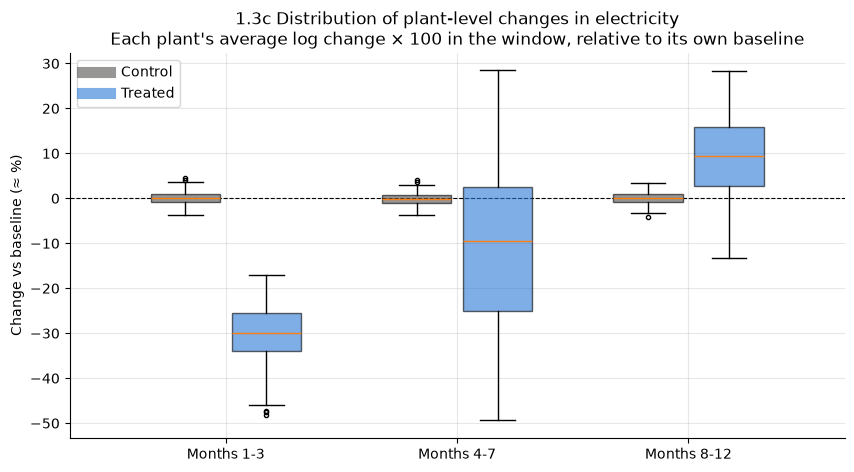

In [45]:
# Distribution of plant-level changes in each post-programme window
post_windows = window_labels[1:]

fig, ax = plt.subplots()
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
for j, g in enumerate(groups):
    data = [100 * plant_windows.loc[(plant_windows["group"] == g) & (plant_windows["window"] == w), "dlog_E"]
            for w in post_windows]
    positions = np.arange(len(post_windows)) + (j - 0.5) * 0.35
    box = ax.boxplot(data, positions=positions, widths=0.3, patch_artist=True, showfliers=True,
                     flierprops={"markersize": 3})
    for patch in box["boxes"]:
        patch.set_facecolor(group_colours[g])
        patch.set_alpha(0.6)
    ax.plot([], [], color=group_colours[g], linewidth=8, alpha=0.6, label=g)
ax.set_xticks(range(len(post_windows)))
ax.set_xticklabels(post_windows)
ax.set_ylabel("Change vs baseline (≈ %)")
ax.set_title("1.3c Distribution of plant-level changes in electricity\n"
             "Each plant's average log change × 100 in the window, relative to its own baseline")
ax.legend()
plt.show()

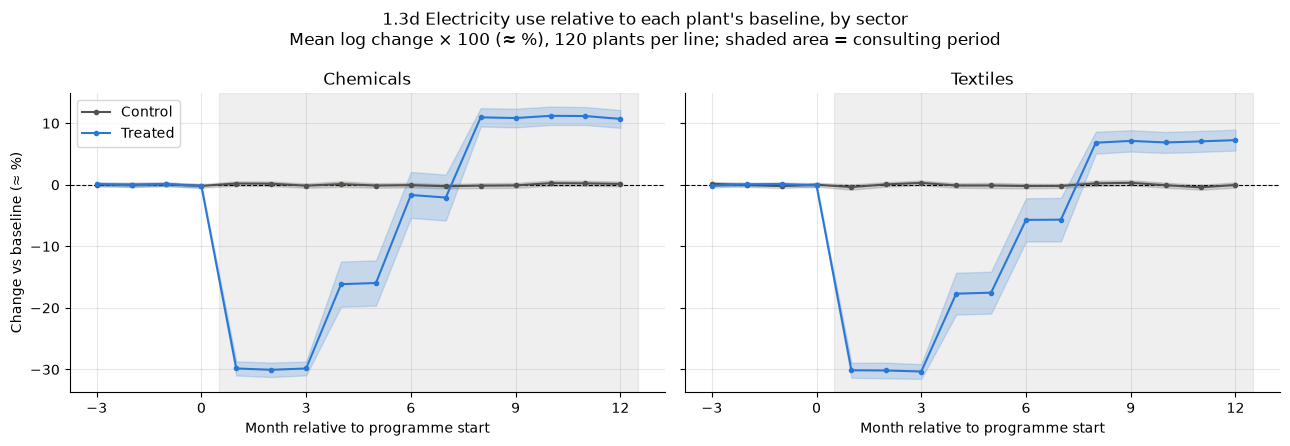

In [76]:
# 1.3d Electricity relative to baseline, by sector and group, with 95% intervals across plants
by_sector = mean_and_ci_by(energy, ["sector", "month", "group"], "dlog_E")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, s in zip(axes, sectors):
    ax.axvspan(0.5, 12.5, color="grey", alpha=0.12)
    ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
    for g in groups:
        d = by_sector[(by_sector["sector"] == s) & (by_sector["group"] == g)]
        ax.fill_between(d["month"], 100 * d["low"], 100 * d["high"], color=group_colours[g], alpha=0.2)
        ax.plot(d["month"], 100 * d["mean"], marker="o", markersize=3, color=group_colours[g], label=g)
    ax.set_title(s)
    ax.set_xticks(range(-3, 13, 3))
    ax.set_xlabel("Month relative to programme start")
axes[0].set_ylabel("Change vs baseline (≈ %)")
axes[0].legend()
fig.suptitle("1.3d Electricity use relative to each plant's baseline, by sector\n"
             "Mean log change × 100 (≈ %), 120 plants per line; shaded area = consulting period")
fig.tight_layout()
plt.show()



# Part 2: Find the question, then develop an explanation

## 2. What does the time pattern tell you?

Look more closely at the evolution of electricity use. Does a single average for the period after consulting give an adequate account? Identify the features of the time path that would matter to a policymaker, and decide how to present them clearly.

Compare your conclusions across treated and control plants and consider whether the average hides differences across firms. State the main empirical pattern that your subsequent analysis needs to explain. Keep a description of that pattern separate from an explanation of why it occurs.

**Overview of Section 2**

* **2.1 A single post-programme average is misleading.** Averaged over months 1–12, treated plants use about 7% less electricity. That number hides a 26% saving at first and a 9% *increase* later.
* **2.2 The rise happens in one step, exactly when labour becomes adjustable.** In each staffing-review cohort, treated plants' electricity jumps from about −26% to about +9% in the review month (4, 6 or 8) and then stays flat to month 12. The apparent "three step increase" in the pooled average is just the three cohorts switching at different dates.
* **2.3 Labour and output jump at the same moment**, by about +48% and +22%, and are flat before and after. Control plants do not change in any cohort.
* **2.4 The average hides large differences across plants.** The initial saving is similar across plants (about −26%), but the later change ranges from about −12% to +33%. It is larger in Chemicals and rises steadily with the share of electricity in a plant's variable costs.
* **2.5 Electricity and Labour** Electricty and labour are compliments in producing output. When the consulting period is implemented electricity efficiency rises by 36% and increases.

### 2.1 Is a single post-programme average enough?

**Objective:** Check whether one number for months 1–12 describes the programme's effect on electricity.

Observations:
* Over months 1–12 as a whole, treated plants use about 7% less electricity than at baseline; control plants stay about the same.
* This average combines three very different periods: −26% (months 1–3), −10% (months 4–7) and +9% (months 8–12). From a policy analysis, the "-7%" would suggest electricity is saved, whereas by the end of the panel treated plants use *more* than before.


In [79]:
# Each plant's average log change vs its own baseline, for the whole post period and for each window
post = energy[energy["month"] >= 1]

plant_post = post.groupby(["firm_id", "group"])["dlog_E"].mean().reset_index()
plant_post["period"] = "Months 1-12 (single average)"

plant_windows_post = (post.groupby(["firm_id", "group", "window"], observed=True)["dlog_E"].mean()
                      .reset_index()
                      .rename(columns={"window": "period"}))
plant_windows_post["period"] = plant_windows_post["period"].astype(str)

period_order = ["Months 1-12 (single average)", "Months 1-3", "Months 4-7", "Months 8-12"]
single_vs_windows = (pd.concat([plant_post, plant_windows_post], ignore_index=True)
                     .groupby(["period", "group"])["dlog_E"]
                     .agg(mean_change_pct=lambda x: pct(x.mean()), sd_across_plants=lambda x: 100 * x.std())
                     .unstack("group")
                     .reindex(period_order)
                     .round(1))
display(single_vs_windows)

mean_change_pct         sd_across_plants        
group                                Control Treated          Control Treated
period                                                                       
Months 1-12 (single average)            -0.0    -6.9              1.1     7.8
Months 1-3                               0.0   -26.0              1.5     6.4
Months 4-7                              -0.1    -9.8              1.3    17.4
Months 8-12                              0.0     9.4              1.3     9.0

### 2.2 Timing: electricity by staffing-review cohort

**Objective:** the pooled average in Section 2.1 rises in steps. Plants are split into cohorts grouped by when their paid labour can be adjusted (month 4, 6 or 8).

Observations:
* In all three cohorts, treated plants' electricity falls by about 26% in month 1 and stays at that level as long as labour is fixed.
* In each cohort, electricity jumps to about 9% above baseline **in the month labour becomes adjustable** (dotted line): month 4, 6 or 8. It does not move in the months just before.
* After the jump, electricity is flat through month 12. There is no further trend within the panel.
* Control plants' electricty usage remains stable in the three cohorts.
* The apparent three step increase  seen in the pooled average of the treated group is actually a composition effect: one third of plants switch in month 4, another third in month 6, the last third in month 8.

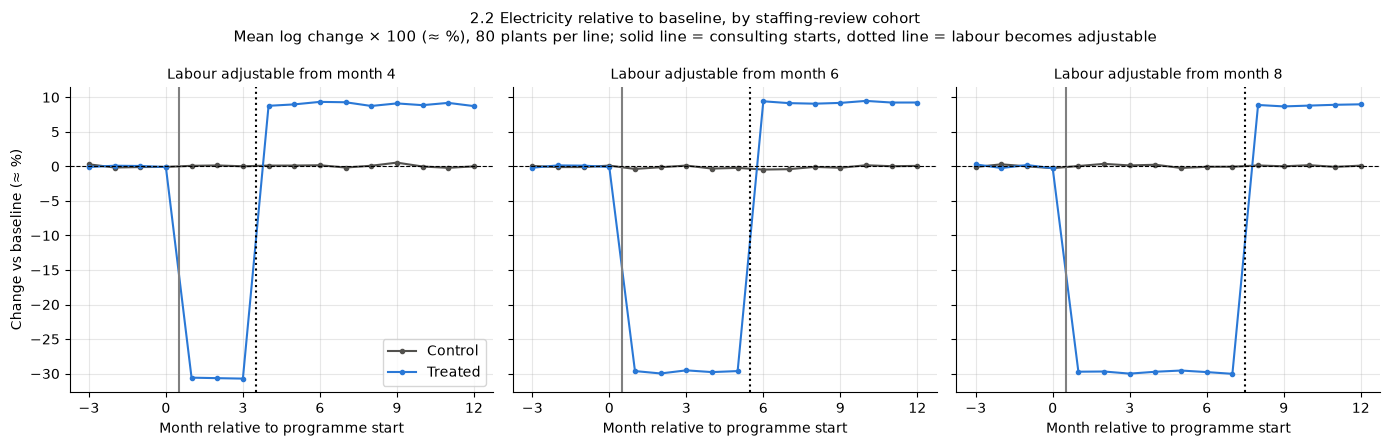

window,Months 1-3,Months 4-7,Months 8-12
adjust_month,,,
4,-26.4,9.5,9.3
6,-25.7,-9.7,9.7
8,-25.8,-25.8,9.3


In [80]:
# Electricity relative to baseline, by staffing-review cohort
by_cohort = energy.groupby(["adjust_month", "month", "group"])["dlog_E"].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, cohort in zip(axes, [4, 6, 8]):
    for g in groups:
        d = by_cohort[(by_cohort["adjust_month"] == cohort) & (by_cohort["group"] == g)]
        ax.plot(d["month"], 100 * d["dlog_E"], marker="o", markersize=3, color=group_colours[g], label=g)
    ax.axvline(0.5, color="grey")
    ax.axvline(cohort - 0.5, color="black", linestyle=":")
    ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
    ax.set_xticks(range(-3, 13, 3))
    ax.set_title(f"Labour adjustable from month {cohort}", fontsize=10)
    ax.set_xlabel("Month relative to programme start")
axes[0].set_ylabel("Change vs baseline (≈ %)")
axes[0].legend()
fig.suptitle("2.2 Electricity relative to baseline, by staffing-review cohort\n"
             "Mean log change × 100 (≈ %), 80 plants per line; solid line = consulting starts, "
             "dotted line = labour becomes adjustable", fontsize=11)
fig.tight_layout()
plt.show()

# Treated plants: mean change (%) by cohort and window
display(energy[(energy["treated"] == 1) & (energy["month"] >= 1)]
        .groupby(["adjust_month", "window"], observed=True)["dlog_E"].mean()
        .pipe(pct)
        .unstack("window")
        .round(1))

### 2.3 Electricity, labour and output around the month labour becomes adjustable

**Objective:** align all plants on the month their labour becomes adjustable and look at the three quantities together.

Observations:
* **When labour is fixed**: treated plants' electricity is about 26% below baseline, while their labour and output are unchanged.
* **When labour is adjustable** electricity, labour and output of treated plants all jump: electricity to about +9%, labour to about +48% and output to about +22% relative to baseline.
* **After labour is adjusted:** all three stay flat. The change is a one-time jump, not a gradual adjustment.
* **Control plants** show no movement in any of the three quantities.

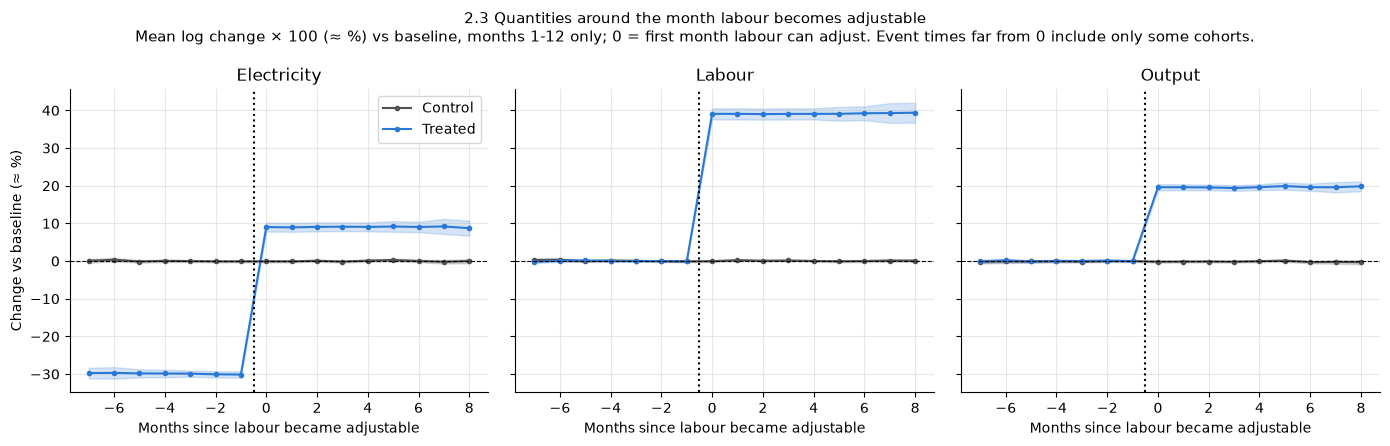

plant_months  electricity_pct  labour_pct  output_pct
group   labour                                                           
Control Adjustable          1680             -0.0         0.1        -0.1
        Fixed               1200             -0.0         0.0        -0.1
Treated Adjustable          1680              9.5        47.9        21.7
        Fixed               1200            -25.9         0.0         0.0

In [81]:
# Quantities around the month labour becomes adjustable (event time 0)
event = energy[energy["month"] >= 1].copy()
event["months_since_labour_adjustable"] = event["month"] - event["adjust_month"]
names = {"dlog_E": "Electricity", "dlog_L": "Labour", "dlog_Q": "Output"}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, (column, label) in zip(axes, names.items()):
    stats_by_time = mean_and_ci_by(event, ["months_since_labour_adjustable", "group"], column)
    for g in groups:
        d = stats_by_time[stats_by_time["group"] == g]
        x = d["months_since_labour_adjustable"]
        ax.fill_between(x, 100 * d["low"], 100 * d["high"], color=group_colours[g], alpha=0.2)
        ax.plot(x, 100 * d["mean"], marker="o", markersize=3, color=group_colours[g], label=g)
    ax.axvline(-0.5, color="black", linestyle=":")
    ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
    ax.set_title(label)
    ax.set_xlabel("Months since labour became adjustable")
axes[0].set_ylabel("Change vs baseline (≈ %)")
axes[0].legend()
fig.suptitle("2.3 Quantities around the month labour becomes adjustable\n"
             "Mean log change × 100 (≈ %) vs baseline, months 1-12 only; 0 = first month labour can adjust. "
             "Event times far from 0 include only some cohorts.", fontsize=11)
fig.tight_layout()
plt.show()

# Mean change (%) while labour is fixed and once it is adjustable (months 1-12)
event["labour"] = np.where(event["labor_adjustable"] == 1, "Adjustable", "Fixed")
display(event.groupby(["group", "labour"])
        .agg(plant_months=("dlog_E", "size"),
             electricity_pct=("dlog_E", lambda x: pct(x.mean())),
             labour_pct=("dlog_L", lambda x: pct(x.mean())),
             output_pct=("dlog_Q", lambda x: pct(x.mean())))
        .round(1))

### 2.4 Does the average hide differences across plants?

**Objective:** compare each treated plant's initial change (months 1–3) with its later change (months 8–12, when all cohorts can adjust labour), and see which plants change most. 

Observations:
* **The initial saving is fairly similar across plants:** in months 1–3 half of the treated plants are between about −29% and −23% (mean −26%; full range about −38% to −16%).
* **The later change varies much more:** from about −12% to +33% in months 8–12. Most treated plants (83%) end above their baseline, but about one in six is still below it.
* **The initial and later changes are almost unrelated** across plants (correlation ≈ −0.1): knowing how much a plant saved at first says little about how much it rebounds.
* **Sector.** The later increase is larger in Chemicals (+12%, 89% of plants above baseline) than in Textiles (+7%, 78%).
* **Electricity cost share.** Since Chemicals plants have higher cost shares on average, part of the sector difference reflects this.

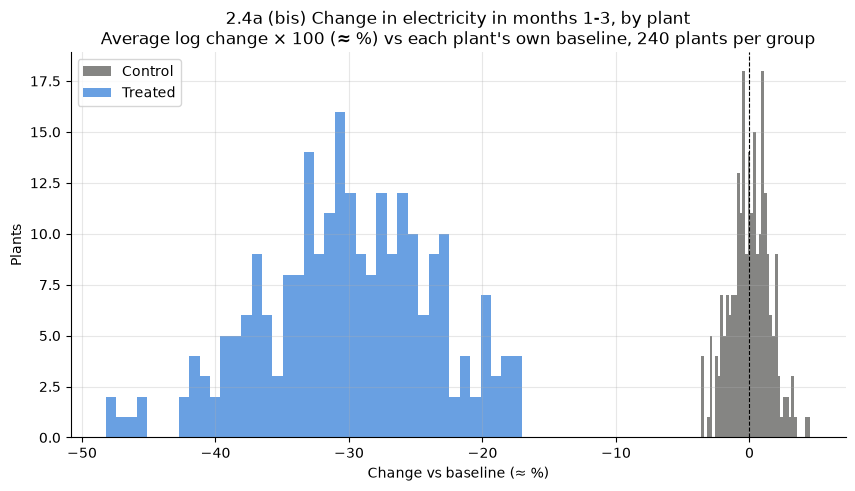

,mean_pct,min_pct,p25_pct,median_pct,p75_pct,max_pct,share_below_baseline
group,,,,,,,
Control,0.0,-3.5,-0.9,0.1,1.0,4.7,0.5
Treated,-26.0,-38.3,-28.8,-25.9,-22.6,-15.7,1.0


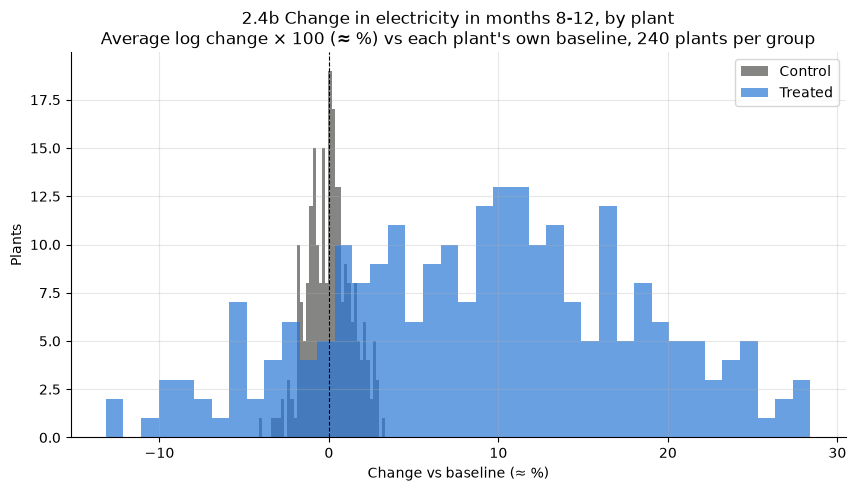

In [85]:
# 2.4a (bis) Change in electricity in months 1-3, by plant
fig, ax = plt.subplots()
for g in groups:
    ax.hist(100 * plant_changes.loc[plant_changes["group"] == g, "initial"], bins=40, alpha=0.7,
            color=group_colours[g], label=g)
ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_xlabel("Change vs baseline (≈ %)")
ax.set_ylabel("Plants")
ax.set_title("2.4a (bis) Change in electricity in months 1-3, by plant\n"
             "Average log change × 100 (≈ %) vs each plant's own baseline, 240 plants per group")
ax.legend()
plt.show()

# Summary of the initial change by group
display(plant_changes.groupby("group")["initial"]
        .agg(mean_pct=lambda x: pct(x.mean()), min_pct=lambda x: pct(x.min()),
             p25_pct=lambda x: pct(x.quantile(0.25)), median_pct=lambda x: pct(x.median()),
             p75_pct=lambda x: pct(x.quantile(0.75)), max_pct=lambda x: pct(x.max()),
             share_below_baseline=lambda x: (x < 0).mean())
        .round(1))

# Each plant's initial (months 1-3) and later (months 8-12) change vs its own baseline
initial = energy[energy["month"].between(1, 3)].groupby("firm_id")["dlog_E"].mean().rename("initial")
later = energy[energy["month"] >= 8].groupby("firm_id")["dlog_E"].mean().rename("later")
plant_changes = plants.join(initial, on="firm_id").join(later, on="firm_id")

# Distribution of later changes
fig, ax = plt.subplots()
for g in groups:
    ax.hist(100 * plant_changes.loc[plant_changes["group"] == g, "later"], bins=40, alpha=0.7,
            color=group_colours[g], label=g)
ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_xlabel("Change vs baseline (≈ %)")
ax.set_ylabel("Plants")
ax.set_title("2.4b Change in electricity in months 8-12, by plant\n"
             "Average log change × 100 (≈ %) vs each plant's own baseline, 240 plants per group")
ax.legend()
plt.show()


In [86]:
# 2.4b Are the initial and later changes related? Treated plants only, one observation per plant.
treated_changes = plant_changes[plant_changes["treated"] == 1].copy()

# 1) Group plants into quartiles by their initial saving (months 1-3) and compare their later change
treated_changes["initial_quartile"] = pd.qcut(treated_changes["initial"], 4,
                                              labels=["Q1 (largest saving)", "Q2", "Q3", "Q4 (smallest saving)"])
display(treated_changes.groupby("initial_quartile", observed=True)
        .agg(plants=("later", "size"),
             initial_change_pct=("initial", lambda x: pct(x.mean())),
             later_change_pct=("later", lambda x: pct(x.mean())),
             later_min_pct=("later", lambda x: pct(x.min())),
             later_max_pct=("later", lambda x: pct(x.max())),
             share_above_baseline_later=("later", lambda x: (x > 0).mean()))
        .round(2))

# 2) Correlation between the initial and later change, with a test of whether it differs from zero
r, p_value = stats.pearsonr(treated_changes["initial"], treated_changes["later"])
print(f"Correlation between initial and later change: {r:.2f} (p-value {p_value:.3f})")
print(f"Share of the variation in the later change explained by the initial change (r squared): {r**2:.1%}")

,plants,initial_change_pct,later_change_pct,later_min_pct,later_max_pct,share_above_baseline_later
initial_quartile,,,,,,
Q1 (largest saving),60,-31.96,10.87,-12.33,32.85,0.82
Q2,60,-27.29,11.14,-9.16,27.52,0.85
Q3,60,-24.27,9.46,-12.23,27.70,0.85
Q4 (smallest saving),60,-19.80,6.29,-8.46,19.93,0.82


Correlation between initial and later change: -0.13 (p-value 0.039)
Share of the variation in the later change explained by the initial change (r squared): 1.8%


In [90]:
# Treated plants: initial and later change by sector and by quartile of electricity cost share
def summarise_changes(data, by):
    return (data.groupby(by)
            .agg(plants=("later", "size"),
                 mean_cost_share=("energy_cost_share", "mean"),
                 initial_change_pct=("initial", lambda x: pct(x.mean())),
                 later_change_pct=("later", lambda x: pct(x.mean())),
                 share_above_baseline_later=("later", lambda x: (x > 0).mean()))
            .round(2))

treated_changes["cost_share_quartile"] = pd.qcut(treated_changes["energy_cost_share"], 4,
                                                 labels=["Q1", "Q2", "Q3", "Q4"])

display(summarise_changes(treated_changes, "sector"))
display(summarise_changes(treated_changes, "cost_share_quartile"))

,plants,mean_cost_share,initial_change_pct,later_change_pct,share_above_baseline_later
sector,,,,,
Chemicals,120,0.71,-25.85,11.60,0.89
Textiles,120,0.65,-26.07,7.28,0.78


,plants,mean_cost_share,initial_change_pct,later_change_pct,share_above_baseline_later
cost_share_quartile,,,,,
Q1,60,0.50,-26.15,-2.49,0.33
Q2,60,0.65,-26.10,6.48,1.00
Q3,60,0.75,-25.14,13.55,1.00
Q4,60,0.84,-26.46,21.58,1.00


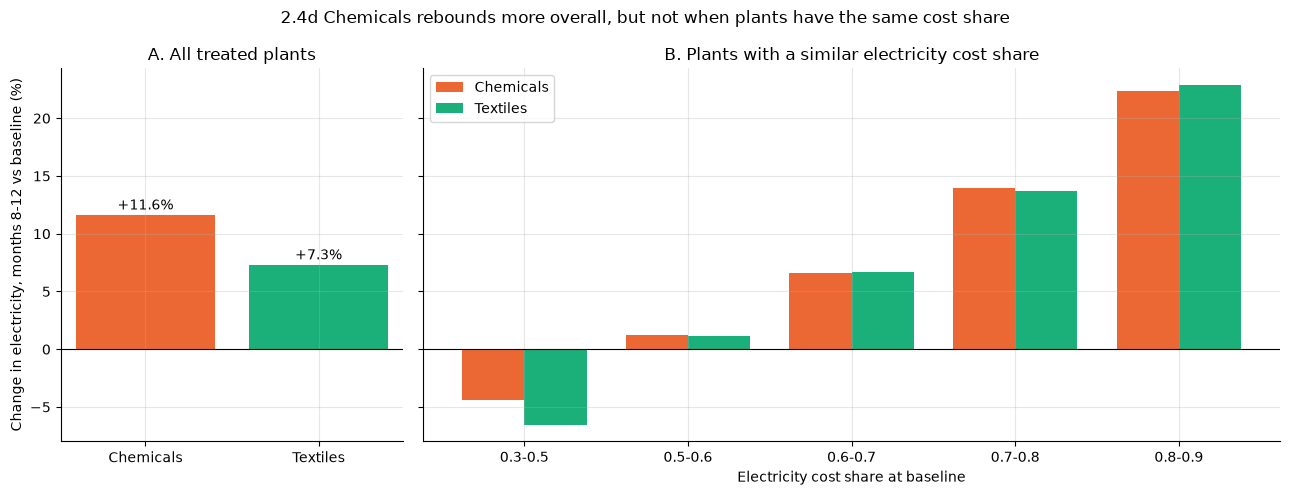

In [89]:
# 2.4d Sector or cost share? Later change in electricity (months 8-12), treated plants
share_bins = [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]
share_labels = ["0.3-0.5", "0.5-0.6", "0.6-0.7", "0.7-0.8", "0.8-0.9"]
treated_changes["cost_share_group"] = pd.cut(treated_changes["energy_cost_share"], bins=share_bins, labels=share_labels)

overall = treated_changes.groupby("sector")["later"].mean().pipe(pct)
by_share = (treated_changes.groupby(["cost_share_group", "sector"], observed=True)["later"].mean()
            .pipe(pct).unstack("sector"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 2.5]}, sharey=True)

# Left: all treated plants in each sector
axes[0].bar(sectors, overall[sectors], color=[sector_colours[s] for s in sectors])
for i, s in enumerate(sectors):
    axes[0].text(i, overall[s] + 0.5, f"{overall[s]:+.1f}%", ha="center")
axes[0].set_title("A. All treated plants")
axes[0].set_ylabel("Change in electricity, months 8-12 vs baseline (%)")

# Right: plants with a similar electricity cost share
x = np.arange(len(share_labels))
for j, s in enumerate(sectors):
    values = by_share[s].reindex(share_labels)
    axes[1].bar(x + (j - 0.5) * 0.38, values, width=0.38, color=sector_colours[s], label=s)
axes[1].set_xticks(x)
axes[1].set_xticklabels(share_labels)
axes[1].set_xlabel("Electricity cost share at baseline")
axes[1].set_title("B. Plants with a similar electricity cost share")
axes[1].legend()

for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
fig.suptitle("2.4d Chemicals rebounds more overall, but not when plants have the same cost share")
fig.tight_layout()
plt.show()

# 2.5 Compliments - Labour and Electricity
Labour and electricty are almost perfect compliments, with a correlation of bout 0.989.

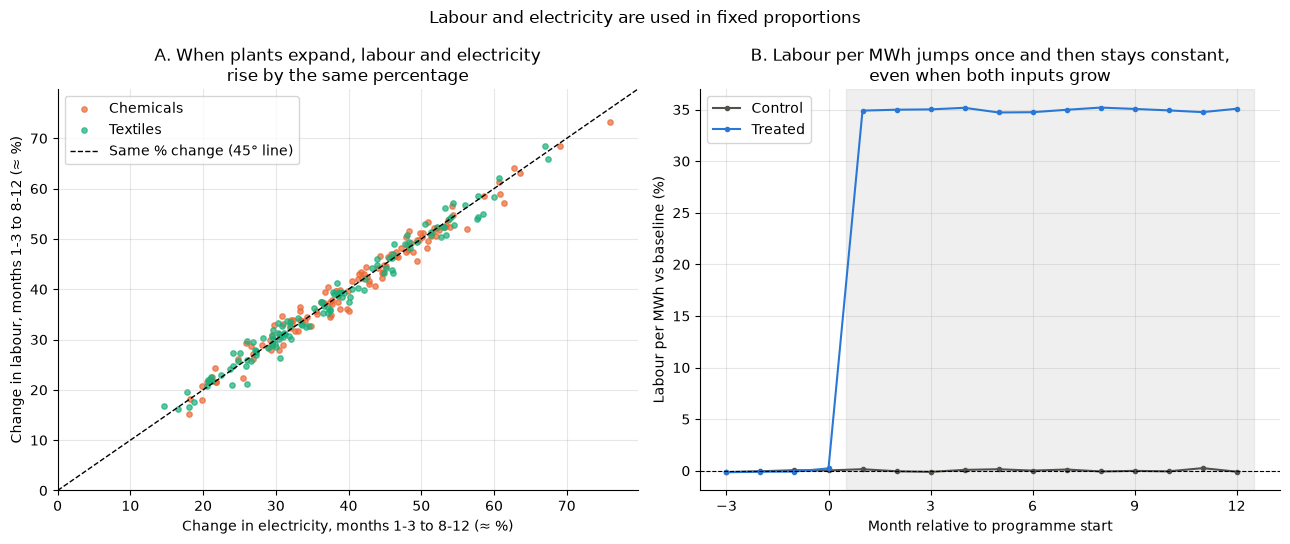

Correlation between the two changes: 0.989
Slope (extra % labour per extra % electricity): 0.97
Mean change: labour 39.1, electricity 39.1 (log points x 100)


In [91]:
# Labour and electricity move together once labour can adjust (treated plants).
# For each plant: change from the short run (months 1-3, labour fixed) to the medium run
# (months 8-12, labour adjustable), in log points x 100 (≈ %).
treated = energy[energy["treated"] == 1]
short_run = treated[treated["month"].between(1, 3)].groupby("firm_id")[["labor", "electricity"]].mean()
medium_run = treated[treated["month"] >= 8].groupby("firm_id")[["labor", "electricity"]].mean()
moves = (100 * np.log(medium_run / short_run)).join(plants.set_index("firm_id")["sector"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Left: change in labour vs change in electricity, one point per plant
ax = axes[0]
for s in sectors:
    d = moves[moves["sector"] == s]
    ax.scatter(d["electricity"], d["labor"], alpha=0.7, s=15, color=sector_colours[s], label=s)
lims = [0, moves[["labor", "electricity"]].max().max() * 1.05]
ax.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="Same % change (45° line)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Change in electricity, months 1-3 to 8-12 (≈ %)")
ax.set_ylabel("Change in labour, months 1-3 to 8-12 (≈ %)")
ax.set_title("A. When plants expand, labour and electricity\nrise by the same percentage")
ax.legend()

# Right: labour per MWh by month, relative to baseline
ratio = energy.assign(L_per_E=energy["labor"] / energy["electricity"])
ratio_base = ratio[ratio["month"] <= 0].groupby("firm_id")["L_per_E"].mean()
ratio["dlog_ratio"] = np.log(ratio["L_per_E"] / ratio["firm_id"].map(ratio_base))
by_month = ratio.groupby(["month", "group"])["dlog_ratio"].mean().reset_index()
ax = axes[1]
ax.axvspan(0.5, 12.5, color="grey", alpha=0.12)
for g in groups:
    d = by_month[by_month["group"] == g]
    ax.plot(d["month"], pct(d["dlog_ratio"]), marker="o", markersize=3, color=group_colours[g], label=g)
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.set_xticks(range(-3, 13, 3))
ax.set_xlabel("Month relative to programme start")
ax.set_ylabel("Labour per MWh vs baseline (%)")
ax.set_title("B. Labour per MWh jumps once and then stays constant,\neven when both inputs grow")
ax.legend()

fig.suptitle("Labour and electricity are used in fixed proportions")
fig.tight_layout()
plt.show()

slope = np.polyfit(moves["electricity"], moves["labor"], 1)[0]
print(f"Correlation between the two changes: {moves['labor'].corr(moves['electricity']):.3f}")
print(f"Slope (extra % labour per extra % electricity): {slope:.2f}")
print(f"Mean change: labour {moves['labor'].mean():.1f}, electricity {moves['electricity'].mean():.1f} (log points x 100)")

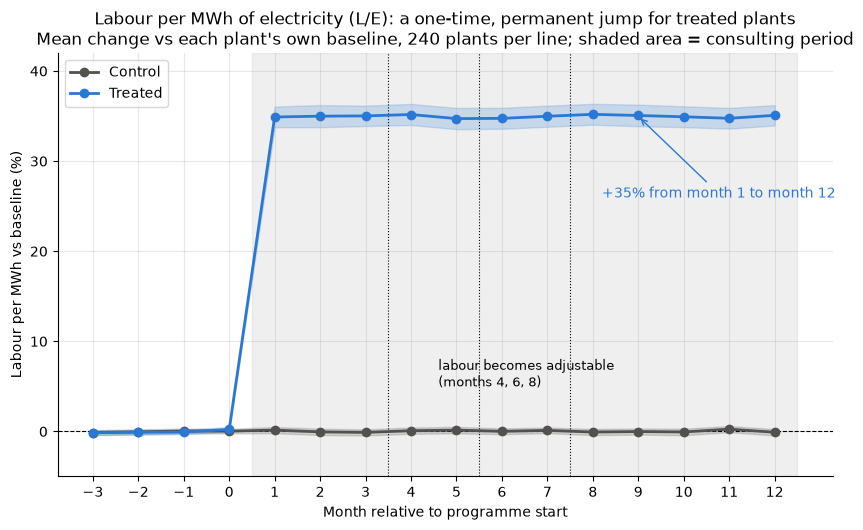

In [93]:
# Labour per MWh of electricity (L/E) by month: treated vs control, with 95% intervals across plants
ratio = energy.assign(L_per_E=energy["labor"] / energy["electricity"])
ratio_base = ratio[ratio["month"] <= 0].groupby("firm_id")["L_per_E"].mean()
ratio["dlog_L_per_E"] = np.log(ratio["L_per_E"] / ratio["firm_id"].map(ratio_base))
by_month = mean_and_ci_by(ratio, ["month", "group"], "dlog_L_per_E")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvspan(0.5, 12.5, color="grey", alpha=0.12)
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
for review_month in [4, 6, 8]:
    ax.axvline(review_month - 0.5, color="black", linestyle=":", linewidth=0.8)
ax.text(4.6, 5, "labour becomes adjustable\n(months 4, 6, 8)", fontsize=9)
for g in groups:
    d = by_month[by_month["group"] == g]
    ax.fill_between(d["month"], pct(d["low"]), pct(d["high"]), color=group_colours[g], alpha=0.2)
    ax.plot(d["month"], pct(d["mean"]), marker="o", color=group_colours[g], linewidth=2, label=g)
treated_level = pct(ratio.loc[(ratio["treated"] == 1) & (ratio["month"] >= 1), "dlog_L_per_E"].mean())
ax.annotate(f"+{treated_level:.0f}% from month 1 to month 12", xy=(9, treated_level),
            xytext=(8.2, treated_level - 9), fontsize=10, color=group_colours["Treated"],
            arrowprops={"arrowstyle": "->", "color": group_colours["Treated"]})
ax.set_xticks(range(-3, 13))
ax.set_ylim(-5, 42)
ax.set_xlabel("Month relative to programme start")
ax.set_ylabel("Labour per MWh vs baseline (%)")
ax.set_title("Labour per MWh of electricity (L/E): a one-time, permanent jump for treated plants\n"
             "Mean change vs each plant's own baseline, 240 plants per line; shaded area = consulting period")
ax.legend(loc="upper left")
plt.show()

### 2.6 The main empirical pattern to explain

*This is a description of what the data show; explanation in Question 4.*

> Consulting reduces treated plants' electricity use by about 26% immediately, with labour and output unchanged. This saving lasts only as long as each plant's paid labour is fixed. In the month a plant's labour becomes adjustable (4, 6 or 8), its electricity, labour and output all rise in a single step, to about +9% for baseline, +48% for labour, and +22% for output relative to baseline, and then stay at that level until month 12. Control plants do not change at any point. The initial saving is similar across plants, but the size of the later increase varies widely and is larger where electricity is a larger share of variable costs. Additionally electricty and labour are almost perfect compliments.

**Features that matter to a policymaker:**
1. **Horizon:** the programme saves electricity in the short run and increases it in the medium run. Any assessment depends on which horizon is used.
2. **Timing:** the switch is tied to when labour can be adjusted, not to time since consulting.
3. **Persistence:** after the switch the new level is stable within the panel, so the medium-run increase does not appear to be temporary, although the measures only continue until the end of the twelve month period.
4. **Other outcomes:** electricity is not the only thing that changes; output and employment rise substantially once labour adjusts.


## 3. Evaluate the programme

Use the random assignment to assess whether consulting achieved its stated objective. Explain your comparison, your choice of outcome and time windows, and why the comparison is informative about the programme rather than simply about differences across plants or changes over time.

Report the size and uncertainty of the effects you consider relevant. Treat plants, rather than their repeated monthly observations, as the independent assignment units. Does the policy assessment depend on the horizon? Be precise about the difference between an average plant’s proportional response and the change in total electricity consumption.

**Overview of Section 3**

* **3.1 Averaged over all consulting months, consulting reduces electricity by about 7%** relative to control plants. This average does not reflect the effects at different horizons.
* **3.2 The assessment depends on the horizon.** Consulting cuts electricity by 26% at the start (months 1–3) and by about 10% in the middle (months 4–7), but *raises* it by about 9% at the end (months 8–12). 
* **3.3Total consumption tells the same story.** Total electricity of treated plants is 26 percentage points lower than control at the start and about 10 points *higher* at the end, around 107,000 MWh a month more than without consulting. The average-plant and total measures differ slightly in months 4–12, because plants of different sizes respond differently.
* **3.4Labour and output do not change at the start, but rise strongly later** (about +48% and +22% at the end). Prices do not change at all.
* **3.5 Conclusion:** the programme achieves its objective only in the short run. By the end of the panel, treated plants use more electricity than they would have without consulting.

### 3.1 The comparison

**Outcome.** The programme's objective is to reduce electricity consumption, so the main outcome is electricity use (MWh per month). This is measured in two ways, to answer different questions:
* **The average plant's proportional change:** each plant's log change relative to its own baseline, averaged across plants. Every plant counts equally.
* **The change in total consumption:** the sum of MWh over all plants in a group. Large plants count more. This is what matters for aggregate electricity demand.

Labour and output help interpret the electricity results, and check that prices did not change.

**Comparison.** For each plant, its average in each period is compared with its own pre-programme average (months −3 to 0), and then compare this change between treated and control plants (difference in differences):

$$\text{Effect} = (\text{change of treated plants}) - (\text{change of control plants})$$

**Why it measures the programme.**
* *Not changes over time:* consulting was randomly assigned, so control plants act as an estimate of what treated plants would have done without consulting. Anything that affects all plants over time (seasonality, common shocks) cancels out. 

* *Not differences across plants:* each plant is compared with itself, which removes permanent differences in size and productivity, including the small baseline imbalance found in Section 1.

**Time windows.** The average over all consulting months (months 1–12) in three periods:
* **Start (months 1–3):** labour is fixed for every plant.
* **Middle (months 4–7):** a transition period that mixes plants that can already adjust labour (review in month 4 or 6) with plants that cannot yet (month 8).
* **End (months 8–12):** labour can be adjusted in every plant.

**Uncertainty.** Plants, not months, are the independent assignment units. The months of each period within each plant are averaged first, so each plant counts once (240 treated, 240 control), and compute 95% intervals and p-values across plants. Averaging months also reduces recording noise. For total consumption, the same comparison as a regression in which each plant is weighted by its baseline electricity use is employed, with standard errors clustered by plant.

In [52]:
# 3.1 Plant-level change by period, for electricity, labour and output

periods = {
    "Months 1-12 (all consulting months)": range(1, 13),
    "Start (months 1-3)": range(1, 4),
    "Middle (months 4-7)": range(4, 8),
    "End (months 8-12)": range(8, 13),
}

# Long format: one row per plant, month and variable, with the plant's own baseline
energy_long = energy.melt(
    id_vars=["firm_id", "group", "treated", "month"],
    value_vars=["electricity", "labor", "output"],
    var_name="variable", value_name="value",
)
base_long = baseline.rename(columns=lambda c: c.replace("_base", "")).stack().rename("base")
base_long.index.names = ["firm_id", "variable"]
energy_long = energy_long.join(base_long, on=["firm_id", "variable"])
energy_long["dlog"] = np.log(energy_long["value"] / energy_long["base"])

# One observation per plant, variable and period: the plant is the unit of analysis
plant_period = pd.concat([
    energy_long[energy_long["month"].isin(months)]
    .groupby(["firm_id", "group", "treated", "variable"])
    .agg(dlog=("dlog", "mean"), value=("value", "mean"), base=("base", "first"))
    .reset_index()
    .assign(period=label)
    for label, months in periods.items()
], ignore_index=True)
plant_period["period"] = pd.Categorical(plant_period["period"], categories=list(periods), ordered=True)

display(pd.crosstab([plant_period["variable"], plant_period["period"]], plant_period["group"]))

group                                            Control  Treated
variable    period                                               
electricity Months 1-12 (all consulting months)      240      240
            Start (months 1-3)                       240      240
            Middle (months 4-7)                      240      240
            End (months 8-12)                        240      240
labor       Months 1-12 (all consulting months)      240      240
            Start (months 1-3)                       240      240
            Middle (months 4-7)                      240      240
            End (months 8-12)                        240      240
output      Months 1-12 (all consulting months)      240      240
            Start (months 1-3)                       240      240
            Middle (months 4-7)                      240      240
            End (months 8-12)                        240      240

### 3.2 Effect on electricity: the average plant

Observations:
* **All consulting months together:** treated plants' electricity falls by about 7% relative to control (95% interval about −8% to −6%). Taken alone, this suggests a modest saving.
* **Start (months 1–3):** a large saving of 26% (−26.6% to −25.4%).
* **Middle (months 4–7):** the saving shrinks to about 10% (−12% to −8%).
* **End (months 8–12):** the effect reverses. Treated plants use about 9% **more** electricity than they would have without consulting (+8% to +11%).
* **Control plants** change by less than 0.1% in every period.
* The effects at the start and at the end are both clearly different from zero (p < 0.001) and have opposite signs. **The policy assessment depends on the horizon.**

In [53]:
# 3.2 Difference in differences by period, one observation per plant.
# Welch t-test across plants; percentages are exp(log change) - 1.

def did_row(d):
    t = d.loc[d["treated"] == 1, "dlog"]
    c = d.loc[d["treated"] == 0, "dlog"]
    effect = t.mean() - c.mean()
    se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    return pd.Series({
        "plants": len(d),
        "treated_change_pct": pct(t.mean()),
        "control_change_pct": pct(c.mean()),
        "effect_pct": pct(effect),
        "ci_low_pct": pct(effect - 1.96 * se),
        "ci_high_pct": pct(effect + 1.96 * se),
        "p_value": stats.ttest_ind(t, c, equal_var=False).pvalue,
    })

did_table = (plant_period.groupby(["variable", "period"], observed=True)
             .apply(did_row, include_groups=False)
             .reset_index())
did_table["plants"] = did_table["plants"].astype(int)
did_table = did_table.round(1).assign(
    p_value=did_table["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.2g}"))

display(did_table[did_table["variable"] == "electricity"])

,variable,period,plants,treated_change_pct,control_change_pct,effect_pct,ci_low_pct,ci_high_pct,p_value
0,electricity,Months 1-12 (all consulting months),480,-6.9,-0.0,-6.9,-7.9,-6.0,<0.001
1,electricity,Start (months 1-3),480,-26.0,0.0,-26.0,-26.6,-25.4,<0.001
2,electricity,Middle (months 4-7),480,-9.8,-0.1,-9.7,-11.7,-7.7,<0.001
3,electricity,End (months 8-12),480,9.4,0.0,9.4,8.1,10.6,<0.001


### 3.3 Effect on electricity: total consumption

The average-plant effect weights every plant equally. Total consumption weights plants by size, and is what matters for aggregate electricity demand.

**How we estimate it.** For each plant we compute its proportional change in electricity, $E_{period}/E_{base} - 1$, and regress it on the treatment indicator, weighting each plant by its baseline electricity $E_{base}$. A weighted average of proportional changes with these weights equals the change in the group's total, so the coefficient on `treated` is (treated total change) − (control total change). Standard errors are clustered by plant, so plants are the independent units. Multiplying the effect by treated plants' baseline total gives the effect in MWh per month.

We can make the following observations:
* **Start (months 1–3):** total electricity of treated plants is 26 percentage points lower than control, about 275,000 MWh a month less than without consulting. Here the two measures coincide, because all plants cut by a similar proportion.
* **Middle (months 4–7):** the total falls by about 7 points, a smaller saving than for the average plant (−10%).
* **End (months 8–12):** total electricity is about 10 points **higher** than control, about 107,000 MWh a month more than without consulting. This is a slightly larger increase than for the average plant (+9%).
* **All consulting months:** about −5 points in total, against −7% for the average plant.
* The gap between the two measures is small: in months 8–12, plants with higher baseline electricity use increase it slightly more in proportion (about +10% in the largest quarter vs +8.5% in the smallest), so the total rises a little more than the average plant suggests. Section 2.4 showed that the later response varies across plants; Question 6(c) returns to which plants respond most.

In [54]:
# 3.3 Change in TOTAL electricity, treated vs control.
# Weighted difference in differences: outcome = proportional change E_period / E_base - 1,
# weights = baseline electricity, so the coefficient on `treated` equals
# (treated total change) - (control total change).
# Robust (HC2) standard errors: with one observation per plant this treats plants as the
# independent units (it is the same as clustering by plant).

def weighted_effect(y, treated, w):
    """Weighted regression of y on a constant and `treated`. Returns the coefficient on
    `treated`, its HC2 robust standard error, 95% interval and p-value."""
    X = np.column_stack([np.ones(len(y)), treated])
    sw = np.sqrt(w)
    Xw, yw = X * sw[:, None], y * sw
    XtX_inv = np.linalg.inv(Xw.T @ Xw)
    beta = XtX_inv @ Xw.T @ yw
    resid = yw - Xw @ beta
    leverage = np.einsum("ij,jk,ik->i", Xw, XtX_inv, Xw)
    meat = (Xw * (resid ** 2 / (1 - leverage))[:, None]).T @ Xw
    se = np.sqrt((XtX_inv @ meat @ XtX_inv)[1, 1])
    df = len(y) - 2
    t_crit = stats.t.ppf(0.975, df)
    return {"effect": beta[1], "se": se, "low": beta[1] - t_crit * se, "high": beta[1] + t_crit * se,
            "p_value": 2 * stats.t.sf(abs(beta[1] / se), df)}

electricity_period = plant_period[plant_period["variable"] == "electricity"].copy()
electricity_period["prop_change"] = electricity_period["value"] / electricity_period["base"] - 1

rows = []
for p in periods:
    d = electricity_period[electricity_period["period"] == p]
    t, c = d[d["treated"] == 1], d[d["treated"] == 0]
    fit = weighted_effect(d["prop_change"].to_numpy(), d["treated"].to_numpy(), d["base"].to_numpy())
    rows.append({
        "period": p,
        "treated_total_change_pct": 100 * (t["value"].sum() / t["base"].sum() - 1),
        "control_total_change_pct": 100 * (c["value"].sum() / c["base"].sum() - 1),
        "effect_pp": 100 * fit["effect"],
        "ci_low_pp": 100 * fit["low"],
        "ci_high_pp": 100 * fit["high"],
        "p_value": "<0.001" if fit["p_value"] < 0.001 else f"{fit['p_value']:.2g}",
        "effect_MWh_per_month": fit["effect"] * t["base"].sum(),
    })
total_table = pd.DataFrame(rows).round(1)
display(total_table)

# Average plant vs total, side by side
display(did_table[did_table["variable"] == "electricity"][["period", "effect_pct"]]
        .rename(columns={"effect_pct": "average_plant_effect_pct"})
        .merge(total_table[["period", "effect_pp", "effect_MWh_per_month"]]
               .rename(columns={"effect_pp": "total_effect_pp"}), on="period"))

,period,treated_total_change_pct,control_total_change_pct,effect_pp,ci_low_pp,ci_high_pp,p_value,effect_MWh_per_month
0,Months 1-12 (all consulting months),-4.7,0.0,-4.8,-5.8,-3.7,<0.001,-50661.9
1,Start (months 1-3),-25.8,0.1,-26.0,-26.7,-25.2,<0.001,-275224.7
2,Middle (months 4-7),-7.5,-0.1,-7.4,-9.6,-5.2,<0.001,-78794.8
3,End (months 8-12),10.2,0.1,10.1,8.6,11.5,<0.001,106582.1


,period,average_plant_effect_pct,total_effect_pp,effect_MWh_per_month
0,Months 1-12 (all consulting months),-6.9,-4.8,-50661.9
1,Start (months 1-3),-26.0,-26.0,-275224.7
2,Middle (months 4-7),-9.7,-7.4,-78794.8
3,End (months 8-12),9.4,10.1,106582.1


### 3.4 Labour, output and prices


Observations:
* **Prices** (electricity price, wage, output price) do not change at all within any plant, so they cannot explain the changes over time.
* **Start (months 1–3):** labour and output of treated plants do not change (effects of about 0.1–0.2%, not significant). The 26% electricity saving happens with unchanged production.
* **Middle and end:** labour rises by about 22% and then 48%, and output by about 11% and then 22%, relative to control. Electricity rises over the same periods.
* **Control plants:** no change in labour or output in any period.

In [55]:
# 3.4a Labour and output: difference in differences by period
display(did_table[did_table["variable"] != "electricity"])

# 3.4b Prices are fixed within each plant: largest change (max - min) within any plant, by group
price_range = energy.groupby(["firm_id", "group"])[["energy_price", "wage", "output_price"]].agg(lambda x: x.max() - x.min())
display(price_range.groupby("group").max())

,variable,period,plants,treated_change_pct,control_change_pct,effect_pct,ci_low_pct,ci_high_pct,p_value
4,labor,Months 1-12 (all consulting months),480,25.6,0.1,25.6,24.1,27.0,<0.001
5,labor,Start (months 1-3),480,-0.0,0.1,-0.1,-0.3,0.1,0.28
6,labor,Middle (months 4-7),480,21.7,0.0,21.7,19.0,24.5,<0.001
7,labor,End (months 8-12),480,47.8,0.1,47.6,45.5,49.8,<0.001
8,output,Months 1-12 (all consulting months),480,12.1,-0.1,12.2,11.6,12.9,<0.001
9,output,Start (months 1-3),480,0.0,-0.1,0.2,-0.1,0.4,0.2
10,output,Middle (months 4-7),480,10.4,-0.1,10.5,9.2,11.7,<0.001
11,output,End (months 8-12),480,21.6,-0.1,21.7,20.8,22.7,<0.001


,energy_price,wage,output_price
group,,,
Control,0.0,0.0,0.0
Treated,0.0,0.0,0.0


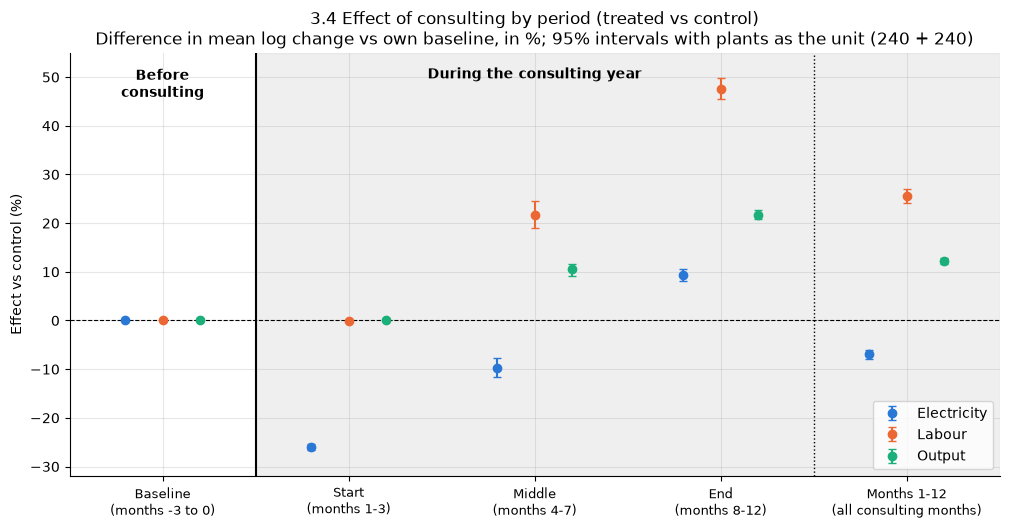

In [94]:
# 3.4c Effects on electricity, labour and output by period, with 95% intervals
variable_names = {"electricity": "Electricity", "labor": "Labour", "output": "Output"}
variable_colours = {"Electricity": "#2a78d6", "Labour": "#eb6834", "Output": "#1baf7a"}

# Order on the x-axis: baseline, the three consulting periods, then the 12-month average
order = ["Baseline (months -3 to 0)", "Start (months 1-3)", "Middle (months 4-7)",
         "End (months 8-12)", "Months 1-12 (all consulting months)"]
positions = {p: i for i, p in enumerate(order)}

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axvspan(0.5, 4.5, color="grey", alpha=0.12)                      # the consulting year
ax.axvline(0.5, color="black", linewidth=1.5)                         # before | during consulting
ax.axvline(3.5, color="black", linestyle=":", linewidth=1)            # periods | 12-month average
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.text(0, 52, "Before\nconsulting", ha="center", va="top", fontsize=10, fontweight="bold")
ax.text(2, 52, "During the consulting year", ha="center", va="top", fontsize=10, fontweight="bold")

for j, (v, label) in enumerate(variable_names.items()):
    d = did_table[did_table["variable"] == v]
    x = np.array([positions[str(p)] for p in d["period"]]) + (j - 1) * 0.2
    ax.errorbar(x, d["effect_pct"],
                yerr=[d["effect_pct"] - d["ci_low_pct"], d["ci_high_pct"] - d["effect_pct"]],
                fmt="o", capsize=3, color=variable_colours[label], label=label)
    # Baseline: zero by construction (each plant is compared with its own baseline)
    ax.plot(0 + (j - 1) * 0.2, 0, "o", color=variable_colours[label])

ax.set_xticks(range(len(order)))
ax.set_xticklabels([p.replace(" (", "\n(") for p in order], fontsize=9)
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-32, 55)
ax.set_ylabel("Effect vs control (%)")
ax.set_title("3.4 Effect of consulting by period (treated vs control)\n"
             "Difference in mean log change vs own baseline, in %; 95% intervals with plants as the unit (240 + 240)")
ax.legend(loc="lower right")
plt.show()

### 3.5 Assessment

* **Did consulting achieve its objective?** Only in the short run. While labour is fixed, consulting cuts electricity by about 26%, for the average plant and in total. Once plants can adjust labour, the effect reverses: by months 8–12 treated plants use about 9% more electricity (average plant) and about 10% more in total, roughly 107,000 MWh a month, than they would have without consulting.
* **Does the assessment depend on the horizon?** Yes, completely. A single average over months 1–12 (about −7%) would wrongly suggest a lasting saving. The relevant horizon for policy is the end of the panel, when all plants have adjusted, and there the programme increases electricity use.
* **Average plant vs total:** the two measures agree on sign and rough size at every horizon. Total consumption rises slightly more than the average plant's use at the end, because larger electricity users increase their use slightly more in proportion.
* **What else changes:** the electricity increase comes with large increases in labour and output; prices do not change. Electricity savings are therefore not the only consequence of the programme.

## 4. Use Unit 3 to make sense of the findings

Imagine that plant $i$ has the technology

$$q = A_i\sqrt{\min\{L,\ \eta E\}}.$$

$A_i > 0$ is persistent plant productivity; $\eta > 0$ measures the energy services obtained from physical electricity, in units comparable with labor. Consulting aims to improve $\eta$. Neither its initial level nor its realised percentage change is supplied. Plants take their observed prices as given and seek to maximise operating profits, $pq - wL - cE$.

*Institutional context.* Before the intervention plants could choose all inputs. From month 1, pre-existing staffing commitments fix paid labor until the recorded adjustment month (4, 6 or 8). From that month onward labor can adjust freely; electricity can always adjust. These dates were assigned independently of plant characteristics before treatment assignment, and controls face the same arrangements. Assume no other variable inputs, inventory accumulation, entry or exit.

Use the theory learned in Unit 3 to construct an explanation for the findings so far and how they vary across horizons. State the assumptions your argument requires and support it with the calculations and economic diagrams you judge necessary. Decide which choices and constraints matter at each horizon; do not stop at a verbal story loosely connected to the model.

Explain what your account would lead you to look for elsewhere in the data. Distinguish properties assumed by the technology from conclusions supported by observed behaviour. You do not need to estimate a substitution elasticity.

### 4.1 Assumptions

**Assumed by the model (not tested here):**




# Part 3: Turn your explanation into further evidence

## 5. Can the initial response reveal the efficiency gain?

The programme assigns consulting, not a known percentage increase in efficiency. Using your explanation from Question 4, can you use the observations before the intervention and in months 1–3 to estimate the technological effect of consulting?

Explain which observed quantities you need and why. In particular, establish the conditions under which the initial electricity response is informative about efficiency, and check whether the accompanying observations support those conditions. Distinguish the level of η from its percentage change, and use the control plants to assess the change attributable to consulting. Allow for recording noise by combining observations where
appropriate.

Then investigate whether the efficiency change you infer appears to persist later. Explain how you would assess this once other input quantities can change. Be clear about which parts of the conclusion depend on the proposed technology.

In [57]:
#*Answer:*

## 6. Does your explanation predict more than the initial pattern?

A convincing mechanism should generate additional, testable implications. Derive predictions from your explanation and choose new tables, figures or comparisons to investigate each of the following.

    (a) The magnitude of later choices. Does profit maximisation predict plants’ later output and input quantities accurately? Use only baseline observations and months 1–3 to recover any required plant parameters. Make predictions before comparing them with the held-out observations in months 9–12. Examine discrepancies as well as fit.

    (b) Production and electricity. Is the observed change in production large enough to account for the later electricity response, given the efficiency change you estimated? Derive a quantitative criterion and identify which plants meet it. A matching sign alone is not sufficient.

    (c) Differences across firms. According to your mechanism, which pre-intervention characteristics should predict the strongest later electricity responses? Derive and investigate that prediction. Distinguish differences in the size of the efficiency improvement from differences in firms’ responses to a given improvement.

    (d) Input relationships and timing. What relationships between labor and electricity changes should your explanation imply? Do these differ when you compare later observations with baseline rather than with the initial post-intervention period? Investigate these relationships and whether the timing of responses is consistent with the institutional setting.

Explain what each piece of evidence establishes. Distinguish predictions tested against additional observations from identities built from the same quantities. Consider at least one alternative explanation, what would distinguish it from yours, and any limits of the available evidence.

In [58]:
#*Answer:*

# Part 4: Turn your explanation into further evidence

## 7. Evaluate a further efficiency improvement

Suppose a follow-up programme could raise each treated plant’s current η by a further 20%, with Ai and prices unchanged. This is additional to the original intervention; there are no observations from the proposed programme.
Predict output, labor, electricity and operating profits with labor first fixed at the current medium-run level, then freely adjustable. Compare both scenarios with the same no-follow-up baseline. Aggregate the results and examine differences across plants. Explain why extrapolating the original percentage effect might be misleading. Profits exclude the unknown cost of delivering consulting.

*Optional policy extension.* After the original intervention, what plant-specific electricity levy would keep medium-run electricity use at or below its pre-intervention level? Set the levy to zero where none is needed. Let plants reoptimise; report output, profits and tax revenue. Explain why this is not an estimate of an optimal environmental tax or necessarily a feasible uniform policy.

In [59]:
#*Answer:*

## 8. Brief the policymaker

Write a 200–300 word briefing assessing the original programme and the proposed follow-up. Explain the mechanism in plain language, ground your recommendation in evidence and uncertainty, and identify the most useful additional information or policy test.

Distinguish electricity savings from output, private profits and social welfare. Environmental damages and programme-delivery costs are not observed. There is no prescribed policy recommendation.

In [60]:
#*Answer:*